# MLP

## Notes
- The files have already been split into training, validation, and testing sets:
  - `train_ecg.ipynb`
  - `validation_ecg.ipynb`
  - `testing_ecg.ipynb` (not yet provided)
  - In-notebook partitioning, `train_test_split()`, is not needed.

## File Conversion

### Imports

In [1]:
# General Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Load the metadata
META_raw         = pd.read_csv('train_metadata.csv')
META_raw.columns = META_raw.columns.str.strip() # Drops leading/trailing whitespace in column names
META_raw         = META_raw.replace("NA", np.nan)
META = META_raw.dropna()

In [3]:
# Load the ECG
TRAIN_ECG  = np.load('train_ecg.npz')
TRAIN_ECGx = TRAIN_ECG['X']
TRAIN_ECGy = TRAIN_ECG['y']

VALID_ECG  = np.load('validation_ecg.npz')
VALID_ECGx = VALID_ECG['X']
VALID_ECGy = VALID_ECG['y']

# Convert the dictionary-like npz contents into a Pandas DataFrame
# Assumes arrays have the same lengths/shapes
df_train = pd.DataFrame(TRAIN_ECGx, columns=[f'x_{i+1}' for i in range(TRAIN_ECGx.shape[1])])
df_train['target'] = TRAIN_ECGy

df_valid = pd.DataFrame(VALID_ECGx, columns=[f'x_{i+1}' for i in range(VALID_ECGx.shape[1])])
df_valid['target'] = VALID_ECGy

In [4]:
df_train.head()

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_244,x_245,x_246,x_247,x_248,x_249,x_250,x_251,x_252,target
0,-0.305,-0.310,-0.300,-0.305,-0.290,-0.300,-0.300,-0.305,-0.305,-0.290,...,-0.300,-0.315,-0.315,-0.315,-0.330,-0.315,-0.320,-0.315,-0.325,0
1,-0.330,-0.345,-0.345,-0.355,-0.350,-0.340,-0.330,-0.340,-0.340,-0.340,...,-0.360,-0.350,-0.350,-0.355,-0.360,-0.355,-0.365,-0.355,-0.350,0
2,-0.375,-0.385,-0.355,-0.360,-0.355,-0.360,-0.360,-0.370,-0.360,-0.345,...,-0.320,-0.315,-0.325,-0.335,-0.330,-0.315,-0.320,-0.320,-0.330,0
3,-0.345,-0.345,-0.350,-0.355,-0.345,-0.330,-0.330,-0.335,-0.335,-0.340,...,-0.340,-0.325,-0.325,-0.320,-0.315,-0.335,-0.335,-0.345,-0.335,0
4,-0.340,-0.340,-0.340,-0.325,-0.325,-0.325,-0.345,-0.350,-0.340,-0.330,...,-0.295,-0.300,-0.305,-0.310,-0.325,-0.325,-0.315,-0.310,-0.315,0


In [5]:
df_valid.head()

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_244,x_245,x_246,x_247,x_248,x_249,x_250,x_251,x_252,target
0,-0.345,-0.345,-0.350,-0.360,-0.355,-0.345,-0.365,-0.395,-0.400,-0.395,...,-0.255,-0.250,-0.230,-0.225,-0.225,-0.205,-0.20,-0.215,-0.250,0
1,-0.275,-0.280,-0.300,-0.335,-0.325,-0.325,-0.325,-0.330,-0.340,-0.310,...,-0.350,-0.340,-0.335,-0.335,-0.345,-0.325,-0.33,-0.345,-0.345,0
2,-0.340,-0.325,-0.325,-0.310,-0.315,-0.305,-0.290,-0.285,-0.285,-0.310,...,-0.330,-0.335,-0.340,-0.320,-0.285,-0.265,-0.28,-0.290,-0.315,0
3,-0.340,-0.330,-0.330,-0.335,-0.305,-0.310,-0.295,-0.325,-0.340,-0.340,...,-0.390,-0.395,-0.390,-0.365,-0.370,-0.375,-0.38,-0.365,-0.345,0
4,-0.420,-0.405,-0.390,-0.370,-0.380,-0.380,-0.395,-0.400,-0.395,-0.385,...,-0.345,-0.345,-0.355,-0.350,-0.350,-0.355,-0.34,-0.355,-0.355,0


In [6]:
{
    'df_train': df_train.shape,
    'df_valid': df_valid.shape,
}

{'df_train': (51182, 253), 'df_valid': (15367, 253)}

In [7]:
df_train['target'].value_counts()

target
0    46397
1     4785
Name: count, dtype: int64

In [8]:
df_valid['target'].value_counts()

target
0    13892
1     1475
Name: count, dtype: int64

## MLP NN

### To-Do
- ✅ Add to the following to import along with others that may be unlisted:
  - ☑️ `from torch import nn`
- ✅ Define `fit(model_class)` function.
- ✅ Define `MLP(nn.Module)` class.
- ✅ Set `mlp` to `fit(MLP)`
- ❌ Backpropagation test
  - ✖️ Check `Week11_Day2_Neural_Network_Programming.ipynb` - Part 4

### Imports

In [9]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

In [10]:
SEED = 825
torch.manual_seed(SEED)                                               # Set the random seed for reproducibility
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Set the device to GPU if available, otherwise CPU

criterion = nn.CrossEntropyLoss() # Loss Function for multi-class classification
EPOCHS = 100

#### Convert DataFrames to Tensor DataSets

In [11]:
def to_tensor_dataset(df):
    '''
    Substitute to **W11_D2**'s `balanced_subset()` function. \n
    Converts a DataFrame into a PyTorch TensorDataset.
    '''
    # Extract features and labels
    X = df.drop(columns=['target']).values
    y = df['target'].values
    
    # Convert to PyTorch tensors
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    
    return TensorDataset(X_tensor, y_tensor)

In [12]:
train_data = to_tensor_dataset(df_train)
valid_data = to_tensor_dataset(df_valid)

train_loader = DataLoader(train_data, batch_size=512, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=512, shuffle=False)

In [13]:
print(f"Train DataLoader: {len(train_loader)} batches, each with {train_loader.batch_size} samples")
print(f"Validation DataLoader: {len(valid_loader)} batches, each with {valid_loader.batch_size} samples")

Train DataLoader: 100 batches, each with 512 samples
Validation DataLoader: 31 batches, each with 512 samples


- **DataLoader**
  - Wraps a dataset and turns it into an iterable of batches.

### `fit(model_class)` Function

In [14]:
def fit(model_class, data, isTraining=True):
    # Create instance of model
    model = model_class().to(device)
    loader = DataLoader(
        data, 
        batch_size=512, 
        shuffle   =isTraining,
        generator =torch.Generator().manual_seed(SEED)  # Ensure reproducibility
    )
    optimizer = torch.optim.Adam(
        model.parameters(), 
        lr          =1e-3, 
        weight_decay=1e-3)

    epoch_log, loss_log = [], []
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        loss_proportion = total_loss / len(loader)
        print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {loss_proportion:.4f}")
        epoch_log.append(epoch+1)
        loss_log.append(loss_proportion)
    return model, epoch_log, loss_log

### MLP Class

In [15]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()       # Flattens the input tensor to a 1D tensor
        self.hidden  = nn.Linear(252, 32) # Mapping 252 input features (x_n) to 32 hidden neurons
        self.output  = nn.Linear(32, 2)   # Mapping 32 hidden neurons to 2 output classes (normal/abnormal)
    
    def forward(self, x):
        z = self.hidden(self.flatten(x))
        h = torch.relu(z)
        return self.output(h)

### Training

In [16]:
MLP, MLP_epoch_log, MLP_loss_log = fit(MLP, train_data, isTraining=True)

Epoch 1/100, Loss: 0.1558
Epoch 2/100, Loss: 0.0473
Epoch 3/100, Loss: 0.0288
Epoch 4/100, Loss: 0.0213
Epoch 5/100, Loss: 0.0183
Epoch 6/100, Loss: 0.0164
Epoch 7/100, Loss: 0.0152
Epoch 8/100, Loss: 0.0146
Epoch 9/100, Loss: 0.0136
Epoch 10/100, Loss: 0.0132
Epoch 11/100, Loss: 0.0127
Epoch 12/100, Loss: 0.0124
Epoch 13/100, Loss: 0.0119
Epoch 14/100, Loss: 0.0118
Epoch 15/100, Loss: 0.0115
Epoch 16/100, Loss: 0.0114
Epoch 17/100, Loss: 0.0110
Epoch 18/100, Loss: 0.0110
Epoch 19/100, Loss: 0.0108
Epoch 20/100, Loss: 0.0111
Epoch 21/100, Loss: 0.0108
Epoch 22/100, Loss: 0.0106
Epoch 23/100, Loss: 0.0106
Epoch 24/100, Loss: 0.0106
Epoch 25/100, Loss: 0.0113
Epoch 26/100, Loss: 0.0106
Epoch 27/100, Loss: 0.0101
Epoch 28/100, Loss: 0.0105
Epoch 29/100, Loss: 0.0102
Epoch 30/100, Loss: 0.0106
Epoch 31/100, Loss: 0.0102
Epoch 32/100, Loss: 0.0106
Epoch 33/100, Loss: 0.0102
Epoch 34/100, Loss: 0.0102
Epoch 35/100, Loss: 0.0105
Epoch 36/100, Loss: 0.0099
Epoch 37/100, Loss: 0.0101
Epoch 38/1

**At `EPOCH = 100`:**
- First hiccup at `Epoch 19/100, Loss: 0.0108` before rising at `Epoch 20/100, Loss: 0.0111`
- Lowest possible loss at `Epoch 99/100, Loss: 0.0095`

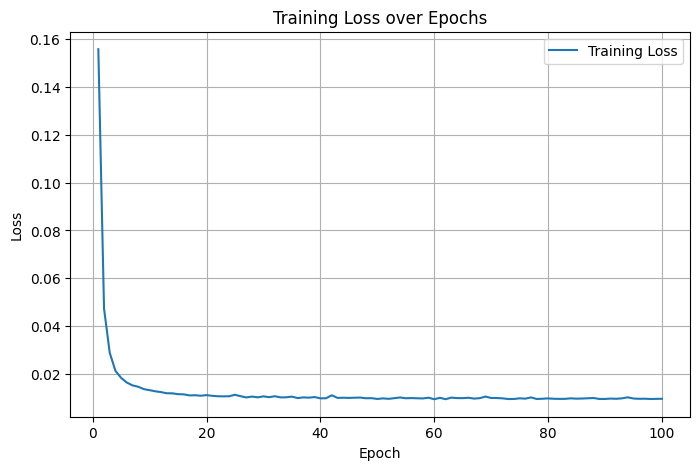

In [17]:
Path("images").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(MLP_epoch_log, MLP_loss_log, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.grid(True)
plt.savefig('images/Training_Loss_over_Epochs.png', dpi=300, bbox_inches='tight')
plt.show()

#### Comparison